# Amazon India Product Sales — Exploratory Data Analysis

**Goal:** Understand pricing, discounting, rating, and category patterns across ~1,465 Amazon India product listings to surface insights that could inform pricing or category strategy.

**Structure of this notebook:**
1. Load & inspect
2. Clean & convert data types
3. Handle missing values
4. Feature engineering
5. Univariate analysis (numeric + categorical + text)
6. Bivariate analysis
7. Multivariate analysis
8. Summary of findings


## 1. Load & Inspect

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

pd.set_option('display.max_columns', None)

In [2]:
AZ = pd.read_csv("amazon.csv")
print("Shape:", AZ.shape)
AZ.head(3)

Shape: (1465, 16)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...


In [3]:
AZ.info()

<class 'pandas.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   product_id           1465 non-null   str  
 1   product_name         1465 non-null   str  
 2   category             1465 non-null   str  
 3   discounted_price     1465 non-null   str  
 4   actual_price         1465 non-null   str  
 5   discount_percentage  1465 non-null   str  
 6   rating               1465 non-null   str  
 7   rating_count         1463 non-null   str  
 8   about_product        1465 non-null   str  
 9   user_id              1465 non-null   str  
 10  user_name            1465 non-null   str  
 11  review_id            1465 non-null   str  
 12  review_title         1465 non-null   str  
 13  review_content       1465 non-null   str  
 14  img_link             1465 non-null   str  
 15  product_link         1465 non-null   str  
dtypes: str(16)
memory usage: 183.3 KB


In [4]:
AZ.isnull().sum()

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

**Observation:** Only `rating_count` shows nulls via `.isnull()` — but several other columns (`discounted_price`, `rating`, etc.) are stored as text with symbols (`₹`, `%`, `,`) or junk values (`'|'`) that hide additional missing/invalid data. Nulls need to be checked *after* cleaning, not just before.

## 2. Clean & Convert Data Types

**Important ordering principle:** clean and convert dtypes *before* imputing missing values. If you impute while a numeric column is still stored as text, `.mean()` isn't available and nulls get filled with the wrong logic (or fail silently).

In [5]:
# Strip currency symbols and commas, convert to float
for col in ['discounted_price', 'actual_price']:
    AZ[col] = AZ[col].replace({'₹': '', ',': ''}, regex=True).astype(float)

# Strip % and convert to float
AZ['discount_percentage'] = AZ['discount_percentage'].str.replace('%', '', regex=False).astype(float)

# Remove thousand separators, convert to numeric (coerce any leftover junk to NaN)
AZ['rating_count'] = pd.to_numeric(AZ['rating_count'].astype(str).str.replace(',', ''), errors='coerce')

# rating column contains a junk value ('|') mixed in with real ratings — coerce turns it into NaN
AZ['rating'] = pd.to_numeric(AZ['rating'], errors='coerce')

AZ.dtypes

product_id                 str
product_name               str
category                   str
discounted_price       float64
actual_price           float64
discount_percentage    float64
rating                 float64
rating_count           float64
about_product              str
user_id                    str
user_name                  str
review_id                  str
review_title               str
review_content             str
img_link                   str
product_link               str
dtype: object

In [6]:
# Now check nulls AFTER conversion — this reveals what was hidden before
AZ.isnull().sum()[AZ.isnull().sum() > 0]

rating          1
rating_count    2
dtype: int64

**Finding:** After conversion, `rating` has 1 null (the `'|'` junk value) and `rating_count` has 2 nulls. Both are a tiny fraction of 1,465 rows.

## 3. Handle Missing Values

**Decision:** since nulls affect only ~2 rows for `rating` and `rating_count` combined (out of 1,465), dropping is more defensible than imputing — we're not inventing a rating or review count for a product that never received one, and the sample loss is negligible.

In [7]:
before = len(AZ)
AZ = AZ.dropna(subset=['rating', 'rating_count'])
print(f"Dropped {before - len(AZ)} rows ({(before - len(AZ)) / before:.2%} of data)")

Dropped 3 rows (0.20% of data)


In [8]:
AZ.drop_duplicates(inplace=True)
print("Shape after dedup:", AZ.shape)

Shape after dedup: (1462, 16)


**Learning point:** mean/mode imputation isn't always the answer — when missingness is small, dropping is simpler, more honest, and avoids injecting values the data never actually contained. Reserve imputation for cases where dropping would lose meaningful data volume.

## 4. Feature Engineering

In [9]:
AZ['savings'] = AZ['actual_price'] - AZ['discounted_price']

cat_split = AZ['category'].str.split('|', expand=True)
AZ['main_category'] = cat_split[0]
AZ['sub_category'] = cat_split[1]

AZ[['savings', 'main_category', 'sub_category']].head(3)

,savings,main_category,sub_category
0,700.0,Computers&Accessories,Accessories&Peripherals
1,150.0,Computers&Accessories,Accessories&Peripherals
2,1700.0,Computers&Accessories,Accessories&Peripherals


In [10]:
# Separate the dataframe into an analytical (numeric/categorical) view and a text view
clean_df = AZ.drop(columns=['about_product', 'user_id', 'user_name', 'review_id',
                             'review_title', 'review_content', 'img_link', 'product_link'])

txt_df = AZ[['product_id', 'review_title', 'review_content', 'rating']].copy()

print(clean_df.columns.tolist())
print(txt_df.columns.tolist())

['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'savings', 'main_category', 'sub_category']
['product_id', 'review_title', 'review_content', 'rating']


In [11]:
clean_df.describe()

,discounted_price,actual_price,discount_percentage,rating,rating_count,savings
count,1462.000000,1462.000000,1462.000000,1462.000000,1462.000000,1462.000000
mean,3129.981826,5453.087743,47.672367,4.096717,18307.376881,2323.105917
std,6950.548042,10884.467444,21.613905,0.289497,42766.096572,4608.569394
min,39.000000,39.000000,0.000000,2.000000,2.000000,0.000000
25%,325.000000,800.000000,32.000000,4.000000,1191.500000,370.250000
50%,799.000000,1670.000000,50.000000,4.100000,5179.000000,800.000000
75%,1999.000000,4321.250000,63.000000,4.300000,17342.250000,1959.000000
max,77990.000000,139900.000000,94.000000,5.000000,426973.000000,61910.000000


**Early red flag worth noting before plotting anything:** for `discounted_price`, `actual_price`, `savings`, and `rating_count`, the mean is several times larger than the median — a strong signal of right skew driven by a handful of outlier products, confirmed visually below.

## 5. Univariate Analysis

### 5a. Numeric columns — distribution shape (histogram) and spread/outliers (box plot)

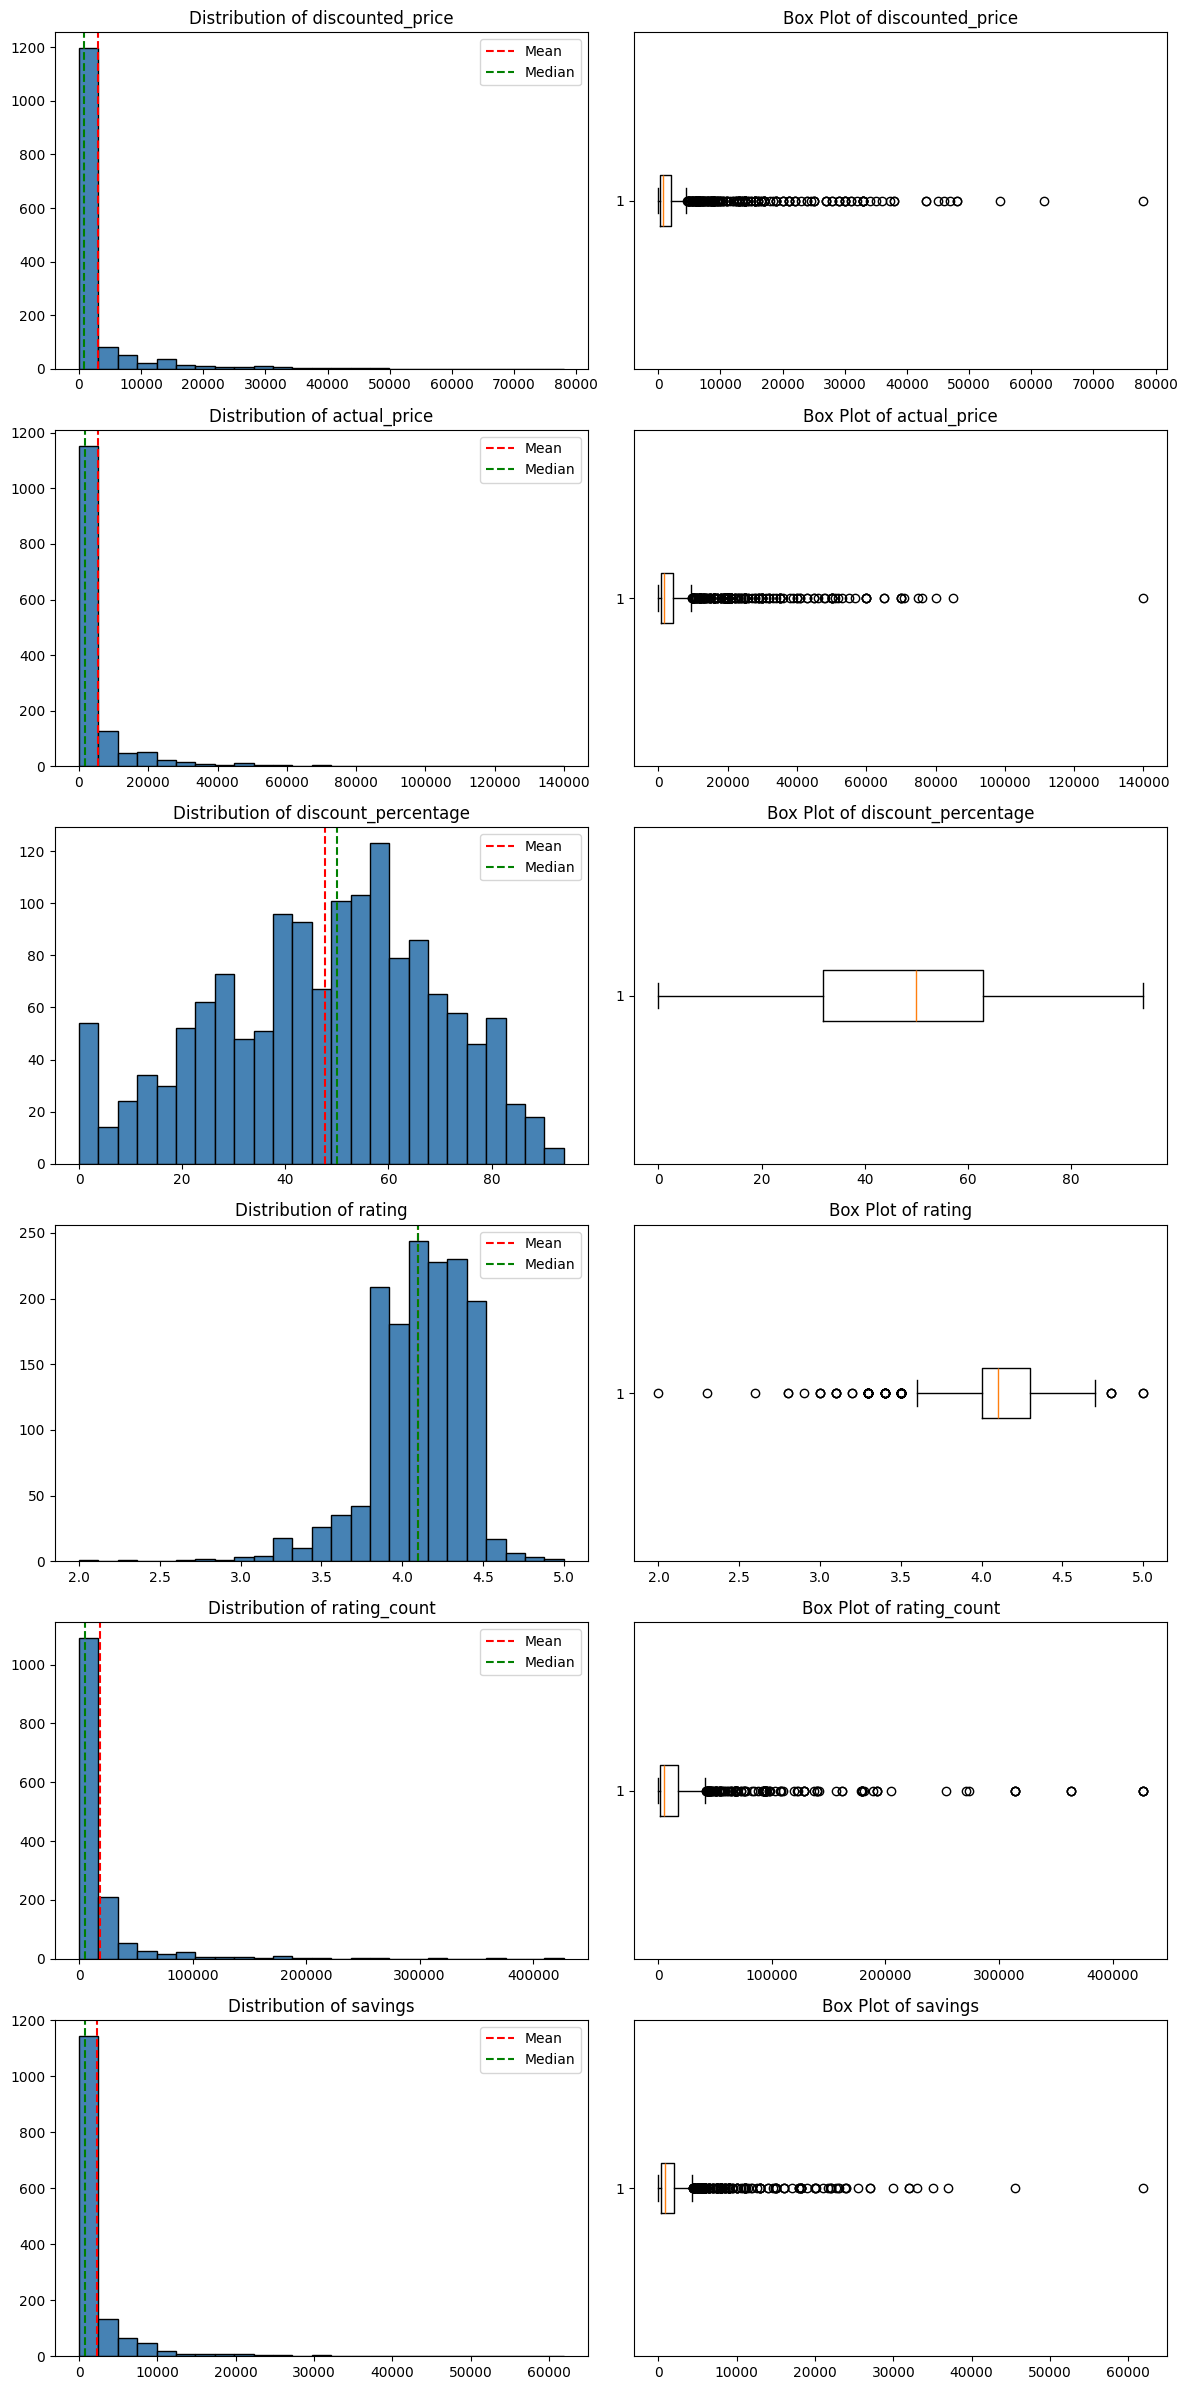

In [12]:
num_cols = clean_df.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(nrows=len(num_cols), ncols=2, figsize=(12, 4 * len(num_cols)))

for i, col in enumerate(num_cols):
    axes[i, 0].hist(clean_df[col], bins=25, color='steelblue', edgecolor='black')
    axes[i, 0].axvline(clean_df[col].mean(), color='red', linestyle='--', label='Mean')
    axes[i, 0].axvline(clean_df[col].median(), color='green', linestyle='--', label='Median')
    axes[i, 0].set_title(f'Distribution of {col}')
    axes[i, 0].legend()

    axes[i, 1].boxplot(clean_df[col], vert=False)
    axes[i, 1].set_title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

In [13]:
# Quantify the skew directly instead of eyeballing it
skew_summary = pd.DataFrame({
    'median': clean_df[num_cols].median(),
    'mean': clean_df[num_cols].mean(),
    'skew': clean_df[num_cols].skew()
})
skew_summary

,median,mean,skew
discounted_price,799.0,3129.981826,4.447620
actual_price,1670.0,5453.087743,4.554997
discount_percentage,50.0,47.672367,-0.290875
rating,4.1,4.096717,-1.257839
rating_count,5179.0,18307.376881,5.672017
savings,800.0,2323.105917,5.017304


**Interpretation:**
- `discounted_price`, `actual_price`, `savings`, and `rating_count` are all heavily right-skewed (skew > 1) — a small number of premium/high-review products pull the mean well above the median. **Median is the representative statistic for these, not mean.**
- `rating` is tightly clustered and roughly symmetric (skew close to 0) — it's naturally bounded (1–5), so it can't skew the way an unbounded price column can.
- `discount_percentage` is close to symmetric, spanning the full 0–100% range without extreme outlier pull.

### 5b. Categorical columns — frequency counts

In [14]:
main_cat_counts = clean_df['main_category'].value_counts().reset_index()
main_cat_counts.columns = ['main_category', 'count']

fig = px.bar(main_cat_counts, x='main_category', y='count',
             title='Product Count by Main Category')
fig.show()

In [15]:
sub_cat_counts = clean_df['sub_category'].value_counts().reset_index()
sub_cat_counts.columns = ['sub_category', 'count']

fig = px.bar(sub_cat_counts.head(15), x='sub_category', y='count',
             title='Top 15 Sub-Categories by Product Count')
fig.show()

**Interpretation:** note which categories dominate the catalog and which are thin — a thin category (only a handful of products) will produce an unreliable-looking box plot later in the bivariate section, since a few products can't represent a "typical" price range for that category.

### 5c. Text column — review content (univariate on the text data)

In [16]:
txt_df['review_length'] = txt_df['review_content'].astype(str).apply(len)

fig = px.histogram(txt_df, x='review_length', nbins=30,
                    title='Distribution of Review Length (characters)')
fig.show()

In [17]:
from collections import Counter
import re

all_text = ' '.join(txt_df['review_content'].astype(str).str.lower())
words = re.findall(r'\b[a-z]{4,}\b', all_text)  # words with 4+ letters, skip short stopword-ish tokens
common_words = Counter(words).most_common(15)

pd.DataFrame(common_words, columns=['word', 'frequency'])

,word,frequency
0,good,6445
1,this,4914
2,product,3945
3,with,3286
4,very,2548
5,quality,2415
6,have,2138
7,that,2132
8,price,1392
9,cable,1380


**Interpretation:** most reviews are short-to-moderate length. The most frequent words give a quick sense of what customers talk about — worth a proper stopword removal pass if you take this further, but even this rough version confirms the text data is usable and not garbage.

## 6. Bivariate Analysis

### 6a. Numeric vs Numeric

In [18]:
fig = px.scatter(clean_df, x='discounted_price', y='rating', trendline='ols',
                  title='Discounted Price vs Rating')
fig.show()

In [19]:
fig = px.scatter(clean_df, x='discount_percentage', y='rating', trendline='ols',
                  title='Discount % vs Rating')
fig.show()

**Interpretation:** if the trendline is close to flat in both plots, that tells you price and discount level have little linear relationship with rating — i.e. cheaper or more heavily discounted products aren't systematically rated worse (or better). Worth stating explicitly rather than leaving the reader to infer it from the chart alone.

### 6b. Numeric vs Categorical

In [20]:
fig = px.box(clean_df, x='main_category', y='discounted_price',
             title='Discounted Price by Main Category')
fig.show()

In [21]:
fig = px.box(clean_df, x='main_category', y='rating',
             title='Rating by Main Category')
fig.show()

**Interpretation:** compare the median line and box width across categories — a category with a much higher median price, or a much wider spread, stands out here in a way the univariate price box plot alone couldn't show.

## 7. Multivariate Analysis

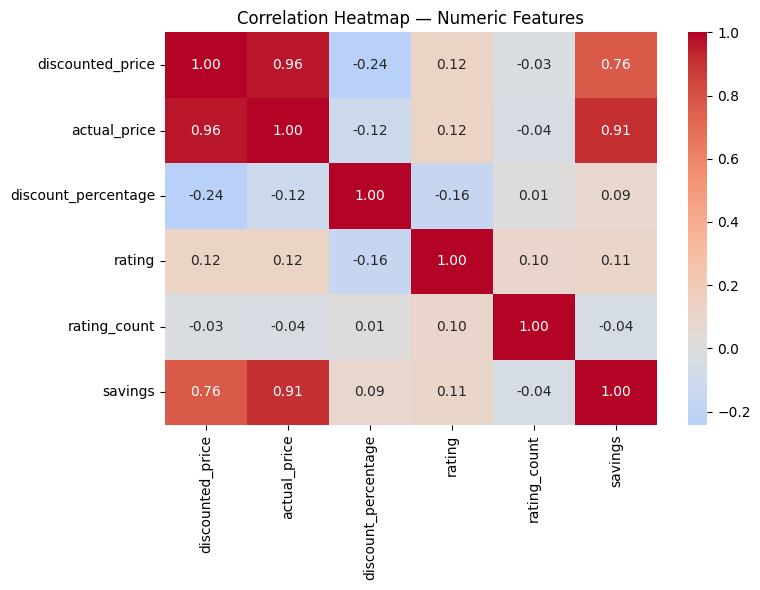

In [22]:
corr = clean_df[['discounted_price', 'actual_price', 'discount_percentage',
                  'rating', 'rating_count', 'savings']].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', ax=ax)
ax.set_title('Correlation Heatmap — Numeric Features')
plt.tight_layout()
plt.show()

In [23]:
fig = px.scatter(clean_df, x='discounted_price', y='rating', color='main_category',
                  title='Price vs Rating, colored by Category',
                  opacity=0.6)
fig.show()

**Interpretation:** the heatmap quantifies what the scatter plots suggested — `actual_price` and `discounted_price` are (unsurprisingly) strongly correlated with each other, while `rating` shows weak correlation with price-related columns. The color-coded scatter shows whether that weak price-rating relationship holds consistently across categories, or if it's masking different patterns within specific categories.

## 8. Summary of Findings

- **Price, savings, and rating_count are heavily right-skewed** — a small number of premium or high-volume outlier products pull the mean well above the median. Median is the more representative statistic for these columns; skew should be considered before feeding them into models that assume normality (or they should be log-transformed).
- **Rating is naturally bounded and symmetric** (mostly 3.5–4.5), unlike price — this is expected given ratings can't run away to extreme values the way price can.
- **Discount percentage and rating show little to no linear relationship** — heavily discounted products aren't systematically rated worse or better.
- **A handful of categories dominate the product catalog**; some sub-categories are thin enough that per-category comparisons for them should be treated cautiously.
- **Missing values were minimal** (~2 rows out of 1,465) — dropped rather than imputed, since the sample loss was negligible and avoids inventing values the data never had.

**Possible next steps:** encode `main_category` for modeling, apply a robust scaler to price columns given the outliers, or build a simple model predicting rating from price/discount/category features.
